In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
import csv
import sys

csv.field_size_limit(sys.maxsize)

df = pd.read_csv(
    "/content/WELFake_Dataset.csv",
    engine="python"
)

In [ ]:
df.shape

(72134, 4)

In [ ]:
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
df.columns


Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
title,558
text,39
label,0


In [ ]:
(df.isnull().sum()/(len(df)))*100

,0
Unnamed: 0,0.000000
title,0.773560
text,0.054066
label,0.000000


In [ ]:
df['label'].value_counts()

,count
label,
1,37106
0,35028


In [ ]:
import seaborn as sns

In [ ]:
import matplotlib.pyplot as plt

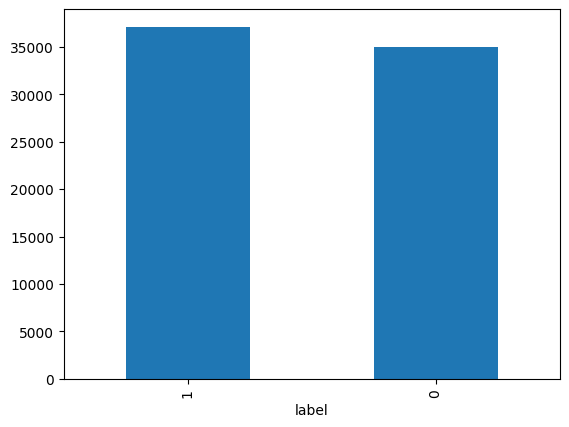

In [ ]:
df['label'].value_counts().plot(kind='bar')
plt.show()

In [ ]:
df[df['title'].isnull()|df['text'].isnull()].head()

,Unnamed: 0,title,text,label
1,1,NaN,Did they post their votes for Hillary already?,1
43,43,NaN,True. Hillary needs a distraction and what bet...,1
162,162,NaN,All eyes on Electoral delegates. The People kn...,1
185,185,NaN,Cool,1
269,269,NaN,A leading US senator: US Supporting War in Syr...,1


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
title,558
text,39
label,0


In [ ]:
df = df.dropna(subset=['text', 'label'])

In [ ]:
df.shape

(72095, 4)

In [ ]:
df['text'].isnull().sum()

np.int64(0)

#Text Preprocessing

In [ ]:
df = df.drop(['Unnamed: 0'],axis = 1)

In [ ]:
df.columns

Index(['title', 'text', 'label'], dtype='object')

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
cv = CountVectorizer()

In [ ]:
corpus = ["the cat is cute","the dog is cool","the cat is fast"]

In [ ]:
X = cv.fit_transform(corpus)

In [ ]:
print(type(cv))

<class 'sklearn.feature_extraction.text.CountVectorizer'>


In [ ]:
print(cv.get_feature_names_out())

['cat' 'cool' 'cute' 'dog' 'fast' 'is' 'the']


In [ ]:
print(X.toarray())

[[1 0 1 0 0 1 1]
 [0 1 0 1 0 1 1]
 [1 0 0 0 1 1 1]]


In [ ]:
df['text'].iloc[0]

'No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizers is called  Sunshine.  She has a radio blog show hosted from Texas called,  Sunshine s F***ing Opinion Radio Show. A snapshot of her #FYF911 @LOLatWhiteFear Twitter page at 9:53 p.m. shows that she was urging supporters to  Call now!! #fyf911 tonight we continue to dismantle the illusion of white Below is a SNAPSHOT Twitter Radio Call Invite   #FYF911The radio show aired at 10:00 p.m. eastern standard time.During the show, callers clearly call for  lynching  and  killing  of white people.A 2:39 minute clip from the radio show can be heard here. It was provided to Breitbart Texas by someone who would like to be referred to

In [ ]:
df['text'] = df['text'].str.lower()

In [ ]:
df['text'].iloc[0]

'no comment is expected from barack obama members of the #fyf911 or #fukyoflag and #blacklivesmatter movements called for the lynching and hanging of white people and cops. they encouraged others on a radio show tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in america.one of the f***yoflag organizers is called  sunshine.  she has a radio blog show hosted from texas called,  sunshine s f***ing opinion radio show. a snapshot of her #fyf911 @lolatwhitefear twitter page at 9:53 p.m. shows that she was urging supporters to  call now!! #fyf911 tonight we continue to dismantle the illusion of white below is a snapshot twitter radio call invite   #fyf911the radio show aired at 10:00 p.m. eastern standard time.during the show, callers clearly call for  lynching  and  killing  of white people.a 2:39 minute clip from the radio show can be heard here. it was provided to breitbart texas by someone who would like to be referred to

In [ ]:
import string

In [ ]:
print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [ ]:
df['text'] = df['text'].str.replace(f"[{string.punctuation}]"," ",
                                    regex = True
    )

In [ ]:
df['text'].iloc[0]

'no comment is expected from barack obama members of the  fyf911 or  fukyoflag and  blacklivesmatter movements called for the lynching and hanging of white people and cops  they encouraged others on a radio show tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in america one of the f   yoflag organizers is called  sunshine   she has a radio blog show hosted from texas called   sunshine s f   ing opinion radio show  a snapshot of her  fyf911  lolatwhitefear twitter page at 9 53 p m  shows that she was urging supporters to  call now    fyf911 tonight we continue to dismantle the illusion of white below is a snapshot twitter radio call invite    fyf911the radio show aired at 10 00 p m  eastern standard time during the show  callers clearly call for  lynching  and  killing  of white people a 2 39 minute clip from the radio show can be heard here  it was provided to breitbart texas by someone who would like to be referred to

In [ ]:
#remove stopwords using natural language processing toolkit

In [ ]:
import nltk

In [ ]:
from nltk.corpus import stopwords

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
stop_words = stopwords.words('english')

In [ ]:
stop_words

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:
stop_words.remove('no')

In [ ]:
stop_words.remove('not')

In [ ]:
stop_words.remove('nor')

In [ ]:
print('not' in stop_words)
print('no' in stop_words)
print('nor' in stop_words)

False
False
False


In [ ]:
sentence = "the government is not good"
words = sentence.split()

In [ ]:
print(words)

['the', 'government', 'is', 'not', 'good']


In [ ]:
filtered_words = [word for word in words if word not in stop_words]

In [ ]:
print(filtered_words)

['government', 'not', 'good']


In [ ]:
"".join(filtered_words)

'governmentnotgood'

In [ ]:
def preprocess_text(text):
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    return " ".join(filtered_words)

In [ ]:
sample = "the government is not good"
print(preprocess_text(sample))

government not good


In [ ]:
df['text']= df['text'].apply(preprocess_text)

In [ ]:
df['text'].iloc[0]

'no comment expected barack obama members fyf911 fukyoflag blacklivesmatter movements called lynching hanging white people cops encouraged others radio show tuesday night turn tide kill white people cops send message killing black people america one f yoflag organizers called sunshine radio blog show hosted texas called sunshine f ing opinion radio show snapshot fyf911 lolatwhitefear twitter page 9 53 p shows urging supporters call fyf911 tonight continue dismantle illusion white snapshot twitter radio call invite fyf911the radio show aired 10 00 p eastern standard time show callers clearly call lynching killing white people 2 39 minute clip radio show heard provided breitbart texas someone would like referred hannibal already received death threats result interrupting fyf911 conference calls unidentified black man said mother f kers start f ing like us bunch ni ers takin one us roll said cause already roll gangs anyway six seven black mother f ckers see white person lynch ass let turn

In [ ]:
print("cleaned text:")
print(df['text'].iloc[0][:500])
print("/nNo of words",len(df['text'].iloc[0].split()))

cleaned text:
no comment expected barack obama members fyf911 fukyoflag blacklivesmatter movements called lynching hanging white people cops encouraged others radio show tuesday night turn tide kill white people cops send message killing black people america one f yoflag organizers called sunshine radio blog show hosted texas called sunshine f ing opinion radio show snapshot fyf911 lolatwhitefear twitter page 9 53 p shows urging supporters call fyf911 tonight continue dismantle illusion white snapshot twitter
/nNo of words 489


In [ ]:
print(df['text'].isnull().sum())

0


In [ ]:
X = cv.fit_transform(df['text'])

In [ ]:
df.shape

(72095, 3)

In [ ]:
X.shape

(72095, 242639)

In [ ]:
print(len(cv.get_feature_names_out()))

242639


In [ ]:
cv_filtered = CountVectorizer(min_df = 5,max_df = 0.95)
X_filtered = cv_filtered.fit_transform(df['text'])

In [ ]:
print(X_filtered.shape)

(72095, 64771)


In [ ]:
X = df['text']

In [ ]:
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify = y)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(57676,)
(14419,)
(57676,)
(14419,)


In [ ]:
cv = CountVectorizer(min_df = 5,max_df = 0.95)

In [ ]:
X_train_vec = cv.fit_transform(X_train)

In [ ]:
X_test_vec = cv.transform(X_test)

In [ ]:
print(X_train_vec.shape)
print(X_test_vec.shape)

(57676, 58649)
(14419, 58649)


In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
nb = MultinomialNB()

In [ ]:
nb.fit(X_train_vec,y_train)

MultinomialNB()

In [ ]:
y_pred  = nb.predict(X_test_vec)

In [ ]:
print(y_pred[:10])

[0 0 1 1 0 0 0 1 1 1]


In [ ]:
print(y_test.iloc[:10].values)

[0 0 1 1 0 0 0 1 1 1]


In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy = accuracy_score(y_test,y_pred)
print(accuracy)

0.898952770649837


In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[6324  682]
 [ 775 6638]]


In [ ]:
from sklearn.metrics import precision_score,recall_score

In [ ]:
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
print("precison:",precision)
print("recall",recall)

precison: 0.9068306010928961
recall 0.8954539322811278


In [ ]:
from sklearn.metrics import f1_score

In [ ]:
f1 = f1_score(y_test,y_pred)
print(f1)

0.9011063598723953


In [ ]:
from sklearn.metrics import classification_report
cr = classification_report(y_test,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.89      0.90      0.90      7006
           1       0.91      0.90      0.90      7413

    accuracy                           0.90     14419
   macro avg       0.90      0.90      0.90     14419
weighted avg       0.90      0.90      0.90     14419



In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lr = LogisticRegression(max_iter = 1000)

In [ ]:
lr.fit(X_train_vec,y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_lr = lr.predict(X_test_vec)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_lr = accuracy_score(y_test,y_pred_lr)
print(accuracy_lr)

0.9630348845273597


In [ ]:
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test,y_pred_lr)
print(cm_lr)

[[6679  327]
 [ 206 7207]]


In [ ]:
from sklearn.metrics import recall_score,precision_score
recall_lr = recall_score(y_test,y_pred_lr)
precision_lr = precision_score(y_test,y_pred_lr)
print("recall:",recall_lr)
print("precision:",precision_lr)

recall: 0.9722109807095642
precision: 0.9565967613485532


In [ ]:
from sklearn.metrics import f1_score
f1_lr = f1_score(y_test,y_pred_lr)
print(f1_lr)

0.9643406703686358


In [ ]:
print("Duplicate articles:", df['text'].duplicated().sum())

Duplicate articles: 9402


In [ ]:
duplicate_groups = (df.groupby('text')['label'].nunique())

In [ ]:
print(duplicate_groups.value_counts())

label
1    62692
2        1
Name: count, dtype: int64


In [ ]:
conflicting_texts = duplicate_groups[duplicate_groups>1].index
for text in conflicting_texts:
    print(df[df['text']==text][['text','label']])

      text  label
7               1
106             1
325             1
364             1
512             1
...    ...    ...
71771           1
71914           1
72026           1
72119           1
72125           1

[745 rows x 2 columns]


In [ ]:
for text in conflicting_texts:
    print(df.loc[df['text'] == text, 'label'].value_counts())

label
1    744
0      1
Name: count, dtype: int64


In [ ]:
conflict = df[df['text'].isin(conflicting_texts)]

In [ ]:
print(conflict[conflict['label']==0].index)

Index([1942], dtype='int64')


In [ ]:
train_articles = set(X_train)
test_articles = set(X_test)

In [ ]:
overlap = train_articles.intersection(test_articles)

In [ ]:
print(len(overlap))

2533


In [ ]:
overlap_texts = X_test[X_test.isin(X_train)]

print("Overlapping articles:", len(overlap_texts))

Overlapping articles: 2801


In [ ]:
overlap_labels = df[df['text'].isin(overlap_texts)]['label'].value_counts()

print(overlap_labels)

label
1    6044
0     318
Name: count, dtype: int64


In [ ]:
overlap_texts = X_test[X_test.isin(X_train)]

In [ ]:
print(len(overlap_texts))

2801


In [ ]:
overlap_labels = df[df['text'].isin(overlap_texts)]['label'].value_counts()

In [ ]:
df_clean = df.drop_duplicates(subset = ['text'])

print("Original rows:", len(df))
print("After deduplication:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

Original rows: 72095
After deduplication: 62693
Removed rows: 9402


In [ ]:
df_clean = df_clean[~df_clean['text'].isin(conflicting_texts)]

In [ ]:
print(df_clean.shape)

(62692, 3)


In [ ]:
print(df_clean['label'].value_counts())

label
0    34618
1    28074
Name: count, dtype: int64


In [ ]:
X_clean = df_clean['text']
y_clean = df_clean['label']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

In [ ]:
print(X_train.shape)
print(X_test.shape)

(50153,)
(12539,)


In [ ]:
cv_clean = CountVectorizer(min_df=5, max_df=0.95,stop_words = stop_words)

X_train_vec = cv_clean.fit_transform(X_train)
X_test_vec = cv_clean.transform(X_test)

In [ ]:
print(X_train_vec.shape)
print(X_test_vec.shape)

(50153, 55058)
(12539, 55058)


In [ ]:
from sklearn.naive_bayes import MultinomialNB
nb_clean = MultinomialNB()
nb_clean.fit(X_train_vec,y_train)
y_pred_nb = nb_clean.predict(X_test_vec)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_nb_clean = accuracy_score(y_test,y_pred_nb)
print(accuracy_nb_clean)

0.8995135178243879


In [ ]:
from sklearn.linear_model import LogisticRegression
lr_clean = LogisticRegression(max_iter =1000)
lr_clean.fit(X_train_vec,y_train)
y_pred_lr_clean = lr_clean.predict(X_test_vec)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_lr_clean = accuracy_score(y_test,y_pred_lr_clean)
print(accuracy_lr_clean)

0.9495175053832045


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr_clean))
print("Precision:", precision_score(y_test, y_pred_lr_clean))
print("Recall:", recall_score(y_test, y_pred_lr_clean))
print("F1 Score:", f1_score(y_test, y_pred_lr_clean))

Accuracy: 0.9495175053832045
Precision: 0.9422940340909091
Recall: 0.945146927871772
F1 Score: 0.9437183248866364


In [ ]:
feature_names = cv_clean.get_feature_names_out()
coefficients = lr_clean.coef_[0]
top_fake = coefficients.argsort()[-20:][::-1]
top_real = coefficients.argsort()[:20]

In [ ]:
print("top 20 features of fake news:")
print(feature_names[top_fake])
print("top 20 features of real news:")
print(feature_names[top_real])

top 20 features of fake news:
['via' 'getty' 'ipsos' 'featured' 'com' 'nyp' 'wfb' 'thomson' 'streamline'
 'flickr' 'october' 'wire' 'snip' 'adler' 'read' 'image' 'nyt' 'please'
 '21wire' 'loading']
top 20 features of real news:
['reuters' 'follow' 'pamkeynen' 'pam' 'twitter' 'siriusxm' '2017' 'milo'
 'protective' 'macron' 'jerome' 'kew' 'jeromeehudson' 'recounts'
 'presumptive' 'monday' 'rest' 'magnifitrent' 'thursday' '2007']


In [ ]:
print("this" in cv_clean.vocabulary_)
print("the" in cv_clean.vocabulary_)
print("what" in cv_clean.vocabulary_)
print("as" in cv_clean.vocabulary_)

False
False
False
False


In [ ]:
print(df_clean['text'].iloc[0][:1000])

no comment expected barack obama members fyf911 fukyoflag blacklivesmatter movements called lynching hanging white people cops encouraged others radio show tuesday night turn tide kill white people cops send message killing black people america one f yoflag organizers called sunshine radio blog show hosted texas called sunshine f ing opinion radio show snapshot fyf911 lolatwhitefear twitter page 9 53 p shows urging supporters call fyf911 tonight continue dismantle illusion white snapshot twitter radio call invite fyf911the radio show aired 10 00 p eastern standard time show callers clearly call lynching killing white people 2 39 minute clip radio show heard provided breitbart texas someone would like referred hannibal already received death threats result interrupting fyf911 conference calls unidentified black man said mother f kers start f ing like us bunch ni ers takin one us roll said cause already roll gangs anyway six seven black mother f ckers see white person lynch ass let turn 

In [ ]:
for word in ['the', 'this', 'what', 'as']:
    print(word, any(word in text.split() for text in X_train))

the False
this False
what False
as False


In [ ]:
for word in ['the', 'this', 'what', 'as']:
    print(word, cv_clean.vocabulary_.get(word))


the None
this None
what None
as None


In [ ]:
cv_clean = CountVectorizer(min_df=5, max_df=0.95)

X_train_vec = cv_clean.fit_transform(X_train)
X_test_vec = cv_clean.transform(X_test)

In [ ]:
for word in ['the', 'this', 'what', 'as']:
    print(word, word in cv_clean.vocabulary_)

the True
this True
what True
as True


In [ ]:
for word in ['the', 'this', 'what', 'as']:
    count = X_train.str.contains(
        rf'\b{word}\b',
        regex=True,
        na=False
    ).sum()
    print(word, count)

the 8729
this 3273
what 2606
as 1109


In [ ]:
sample = X_train.iloc[0]

print(sample[:1000])
print("the" in sample.split())
print("this" in sample.split())

guilt association smear nyt gets virginia dare wrong november 7 2016 10 20 new york times done usual guilt association thing blaming trump us vdare com people like us people don’t even know last would include david duke part mr trump not expressed support white nationalist groups rallied candidacy neither distanced exception david duke former klansman running senate mr trump disavowed initial wavering last winter it’s nonsense say wavered this–see ann coulter’s ann coulter trump wins “disavowal” game super tuesday white nationalists beginning grapple best harness energy campaign stirred mr spencer’s group national policy institute says “dedicated heritage identity future people european descent united states around world ” organizing valedictory conference ronald reagan building washington shortly election aim take stock presidential campaign — “when ideas began invading mainstream” — figure what’s next addition mr spencer speakers include peter brimelow founder vdare com anti immigrat

In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
print(confusion_matrix(y_test,y_pred_lr_clean))
print(classification_report(y_test,y_pred_lr_clean))

[[6599  325]
 [ 308 5307]]
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      6924
           1       0.94      0.95      0.94      5615

    accuracy                           0.95     12539
   macro avg       0.95      0.95      0.95     12539
weighted avg       0.95      0.95      0.95     12539



In [ ]:
print(X_test.shape)
print(y_test.shape)
print(X_test_vec.shape)
print(y_pred.shape)

(12539,)
(12539,)
(12539, 55192)
(14419,)


In [ ]:
errors = X_test[y_pred_lr_clean != y_test]

In [ ]:
print(errors.head())

50102    al gore issued devastating riposte president t...
10494    no one asking bigger question first place need...
30237    rare interview red bull boss austria’s richest...
23920    dear fellow americans day checking various web...
48324    national bureau economic research published pa...
Name: text, dtype: object


In [ ]:
for idx,article in errors.head(5).items():
  print(f"index = {idx}")
  print(article[:500])
  print(""*80)


index = 50102
al gore issued devastating riposte president trump’s executive order energy unleashed trailer inconvenient sequel truth power unlike creaky predecessor — basically extended powerpoint lecture featuring crap animations drowning polar bears fat sweating failed presidential candidate suit clambering onto hydraulic elevator make tendentious whiney point graph — sequel uses shock awe spectacular footage bludgeon audience submission maelstrom brown boiling floodwaters calving glaciers burning mountain

index = 10494
no one asking bigger question first place need import workers countries speak no english 44 americans working full time jobs percentage adult population 18 years older seems like government setting foreign workers potential abuse employers clearly looking way circumvent traditional hiring practices top federal official worker safety said tuesday illinois businessman outrageous behavior bringing mexican workers remove asbestos without safety gear warrants fines nearl

In [ ]:
misclassified = pd.DataFrame({
    "text": X_test[y_test != y_pred_lr_clean],
    "actual": y_test[y_test != y_pred_lr_clean],
    "predicted": y_pred_lr_clean[y_test != y_pred_lr_clean]
})

print(misclassified.head())

                                                    text  actual  predicted
50102  al gore issued devastating riposte president t...       0          1
10494  no one asking bigger question first place need...       1          0
30237  rare interview red bull boss austria’s richest...       0          1
23920  dear fellow americans day checking various web...       0          1
48324  national bureau economic research published pa...       0          1


In [ ]:
misclassified["actual"].value_counts()

,count
actual,
0,325
1,308


In [ ]:
print("Model features:", lr_clean.n_features_in_)
print("Test features:", X_test_vec.shape[1])
print("Vectorizer features:", len(cv_clean.vocabulary_))

Model features: 55058
Test features: 55192
Vectorizer features: 55192


In [ ]:
print(X_train_vec.shape)

(50153, 55192)


In [ ]:
lr_clean = LogisticRegression(max_iter=1000)
lr_clean.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_lr_clean = lr_clean.predict(X_test_vec)

In [ ]:
probs = lr_clean.predict_proba(X_test_vec)

In [ ]:
import numpy as np

mis_idx = np.where(y_test.to_numpy() != y_pred_lr_clean)[0]

for i in mis_idx[:5]:
    print("Actual:", y_test.iloc[i])
    print("Predicted:", y_pred_lr_clean[i])
    print("Probabilities:", probs[i])
    print("-" * 50)

Actual: 0
Predicted: 1
Probabilities: [0.00221714 0.99778286]
--------------------------------------------------
Actual: 1
Predicted: 0
Probabilities: [0.61517588 0.38482412]
--------------------------------------------------
Actual: 1
Predicted: 0
Probabilities: [0.82910524 0.17089476]
--------------------------------------------------
Actual: 0
Predicted: 1
Probabilities: [0.03910717 0.96089283]
--------------------------------------------------
Actual: 0
Predicted: 1
Probabilities: [0.00137778 0.99862222]
--------------------------------------------------


In [ ]:
for i in mis_idx[:10]:
    print("Actual:", y_test.iloc[i])
    print("Predicted:", y_pred_lr_clean[i])
    print("Confidence:", round(max(probs[i]), 4))
    print("Article:", X_test.iloc[i][:300])
    print("=" * 80)

Actual: 0
Predicted: 1
Confidence: 0.9978
Article: al gore issued devastating riposte president trump’s executive order energy unleashed trailer inconvenient sequel truth power unlike creaky predecessor — basically extended powerpoint lecture featuring crap animations drowning polar bears fat sweating failed presidential candidate suit clambering on
Actual: 1
Predicted: 0
Confidence: 0.6152
Article: rtthe father cuban revolution remains unbeaten foes even death look dramatic assassination plots el comandante character assassinations way lsd italian mobsters tuberculosis wetsuit exploding cigar surviving assassination attempts olympic event would win gold medal castro famously quoted saying cuba
Actual: 1
Predicted: 0
Confidence: 0.8291
Article: no one asking bigger question first place need import workers countries speak no english 44 americans working full time jobs percentage adult population 18 years older seems like government setting foreign workers potential abuse employers clear

In [ ]:
article_index = mis_idx[0]

article_vector = X_test_vec[article_index]

contributions = article_vector.multiply(lr_clean.coef_)

feature_names = cv_clean.get_feature_names_out()

contributions = contributions.toarray().flatten()

top_fake = contributions.argsort()[-10:][::-1]
top_real = contributions.argsort()[:10]

print("Words pushing towards FAKE:")
for i in top_fake:
    print(feature_names[i], contributions[i])

print("\nWords pushing towards REAL:")
for i in top_real:
    print(feature_names[i], contributions[i])

Words pushing towards FAKE:
via 4.824858635525694
featured 2.127360894722205
28 2.1011941821218763
trump 1.1746978368533818
mark 1.0935664024101812
taxpayers 0.6447436205988981
enjoy 0.6022337208310345
basically 0.5889372002125779
disgusting 0.5170198049073648
today 0.4989491818143719

Words pushing towards REAL:
2017 -4.06332836787525
follow -2.1833686152269074
march -1.984933892480489
sequel -0.9394427502127453
donald -0.8983720200331176
reason -0.6618524637591253
executive -0.6420330285111426
kind -0.6378080268482442
whose -0.597882489271803
featuring -0.5018527681277893


In [ ]:
from sklearn.svm import LinearSVC
svm_clean = LinearSVC(max_iter=1000)
svm_clean.fit(X_train_vec,y_train)
y_pred_svm = svm_clean.predict(X_test_vec)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score
print("accuracy:",accuracy_score(y_test,y_pred_svm))
print("recall:",recall_score(y_test,y_pred_svm))
print("precision:",precision_score(y_test,y_pred_svm))
print("f1:",f1_score(y_test,y_pred_svm))

accuracy: 0.9424994018661775
recall: 0.93766696349065
precision: 0.9341731724627396
f1: 0.9359168073948982


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clean = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

rf_clean.fit(X_train_vec, y_train)

ypred_rf = rf_clean.predict(X_test_vec)

In [ ]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score
print("accuracy:",accuracy_score(y_test,ypred_rf))
print("recall:",recall_score(y_test,ypred_rf))
print("precision:",precision_score(y_test,ypred_rf))
print("f1:",f1_score(y_test,ypred_rf))

accuracy: 0.9244756360156312
recall: 0.8794300979519145
precision: 0.9481566820276498
f1: 0.9125011549477964


In [ ]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
from xgboost import XGBClassifier
xgb_clean = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

In [ ]:
xgb_clean.fit(X_train_vec, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ypred_xgb = xgb_clean.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, ypred_xgb))
print("Precision:", precision_score(y_test, ypred_xgb))
print("Recall:", recall_score(y_test, ypred_xgb))
print("F1:", f1_score(y_test, ypred_xgb))

Accuracy: 0.9558975994895925
Precision: 0.9389524800554977
Recall: 0.9642030276046305
F1: 0.9514102451454178


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, ypred_xgb))
print(classification_report(y_test, ypred_xgb))

[[6572  352]
 [ 201 5414]]
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      6924
           1       0.94      0.96      0.95      5615

    accuracy                           0.96     12539
   macro avg       0.95      0.96      0.96     12539
weighted avg       0.96      0.96      0.96     12539



In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean["text"]
y = df_clean["label"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (43884,)
Validation: (9404,)
Testing: (9404,)


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
cv_final = CountVectorizer(min_df =5,max_df =0.95,stop_words = stop_words)
X_train_vec = cv_final.fit_transform(X_train)
X_val_vec = cv_final.transform(X_val)
X_test_vec = cv_final.transform(X_test)

In [ ]:
X_train_vec.shape
X_val_vec.shape
X_test_vec.shape

(9404, 51625)

In [ ]:
from xgboost import XGBClassifier

xgb_final = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_final.fit(X_train_vec, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ypred_val = xgb_final.predict(X_val_vec)

print("Accuracy:", accuracy_score(y_val, ypred_val))
print("Precision:", precision_score(y_val, ypred_val))
print("Recall:", recall_score(y_val, ypred_val))
print("F1:", f1_score(y_val, ypred_val))

Accuracy: 0.9533177371331348
Precision: 0.9339622641509434
Recall: 0.9639040607931608
F1: 0.9486969732382844


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

In [5]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=15,
    scoring="f1",
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=1
)

NameError: name 'RandomizedSearchCV' is not defined

In [4]:
xgb_search.fit(X_train_vec, y_train)

NameError: name 'xgb_search' is not defined

In [10]:
import pandas as pd
import numpy as np
import os

# Load the clean dataset
if os.path.exists('cleaned_dataset.csv'):
    df_temp = pd.read_csv('cleaned_dataset.csv')
else:
    # Fallback to the original dataset if clean one doesn't exist
    df_temp = pd.read_csv('/content/WELFake_Dataset.csv')

# Drop any missing values in text or label columns
df_temp = df_temp.dropna(subset=['text', 'label'])

# Inspect the correlation of specific indicator words with the labels.
bias_keywords = ['reuters', 'breitbart', 'nytimes', 'via', 'twitter', 'getty']
bias_analysis = []

for word in bias_keywords:
    # Check if the word is present in the text
    has_word = df_temp['text'].str.contains(rf'\b{word}\b', na=False, case=False)
    total_with_word = has_word.sum()

    if total_with_word > 0:
        # Calculate distribution of ground truth labels for articles containing this word
        label_distribution = df_temp[has_word]['label'].value_counts(normalize=True).to_dict()
        real_pct = label_distribution.get(0, 0) * 100
        fake_pct = label_distribution.get(1, 0) * 100

        bias_analysis.append({
            'Keyword': word,
            'Total Occurrences': total_with_word,
            'Real (%)': f"{real_pct:.2f}%",
            'Fake (%)': f"{fake_pct:.2f}%"
        })

bias_df = pd.DataFrame(bias_analysis)
print("=== Dataset Bias Analysis: Keyword Associations with Labels ===")
display(bias_df)

print("\n=== Explanation ===")
print("If certain publisher names or source words are heavily skewed towards one label (e.g., 99% Real or 99% Fake),")
print("the model likely uses these words as shortcuts (spurious correlations) rather than learning content-based semantics.")

=== Dataset Bias Analysis: Keyword Associations with Labels ===


,Keyword,Total Occurrences,Real (%),Fake (%)
0,reuters,21896,97.81%,2.19%
1,breitbart,2729,66.36%,33.64%
2,nytimes,436,82.11%,17.89%
3,via,11666,8.37%,91.63%
4,twitter,11410,49.46%,50.54%
5,getty,4178,0.36%,99.64%



=== Explanation ===
If certain publisher names or source words are heavily skewed towards one label (e.g., 99% Real or 99% Fake),
the model likely uses these words as shortcuts (spurious correlations) rather than learning content-based semantics.


In [ ]:
print("Best parameters:", xgb_search.best_params_)
print("Best CV F1 score:", xgb_search.best_score_)

Best parameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Best CV F1 score: 0.9541473668035344


In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

best_xgb = xgb_search.best_estimator_

y_pred_tuned = best_xgb.predict(X_val_vec)

print("Accuracy:", accuracy_score(y_val, y_pred_tuned))
print("Precision:", precision_score(y_val, y_pred_tuned))
print("Recall:", recall_score(y_val, y_pred_tuned))
print("F1 Score:", f1_score(y_val, y_pred_tuned))

print(classification_report(y_val, y_pred_tuned))

NameError: name 'xgb_search' is not defined

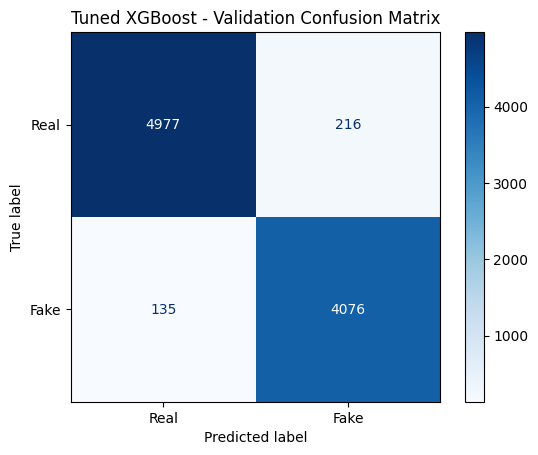

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(cmap="Blues")
plt.title("Tuned XGBoost - Validation Confusion Matrix")
plt.show()

In [ ]:
import pandas as pd

errors = pd.DataFrame({
    "text": X_val,
    "actual": y_val,
    "predicted": y_pred_tuned
})

errors = errors[errors["actual"] != errors["predicted"]]

errors["error_type"] = errors.apply(
    lambda row: "False Positive"
    if row["actual"] == 0
    else "False Negative",
    axis=1
)

print("Total errors:", len(errors))
print(errors["error_type"].value_counts())

Total errors: 351
error_type
False Positive    216
False Negative    135
Name: count, dtype: int64


In [ ]:
# Inspect 5 false positives
fp = errors[errors["error_type"] == "False Positive"]

for i, (idx, row) in enumerate(fp.head(5).iterrows()):
    print(f"\nFALSE POSITIVE {i+1}")
    print("Actual:", "Real")
    print("Predicted:", "Fake")
    print("Article:", row["text"][:700])
    print("-" * 80)


# Inspect 5 false negatives
fn = errors[errors["error_type"] == "False Negative"]

for i, (idx, row) in enumerate(fn.head(5).iterrows()):
    print(f"\nFALSE NEGATIVE {i+1}")
    print("Actual:", "Fake")
    print("Predicted:", "Real")
    print("Article:", row["text"][:700])
    print("-" * 80)


FALSE POSITIVE 1
Actual: Real
Predicted: Fake
Article: asked stars filmmakers holiday traditions edited excerpts answers husband dwyane wade chicago bulls playing christmas day long we’ve together watch husband play basketball christmas goes really depends game goes infamous “kobe shot” ruined christmas big heat win cavs good christmas started seeing dwyane family would listen broadway cast album “dreamgirls” choose different parts years got james early years deena — rare years favorite thing family wasn’t really presents tree loved stockings especially mom’s loved open things we’d wrap like six beautiful boxes she’d think going get necklace something 10 minutes opening packages getting tiffany box would cotton ball still son levi wrapped five b
--------------------------------------------------------------------------------

FALSE POSITIVE 2
Actual: Real
Predicted: Fake
Article: hosted cnn presentation bombastically stupid almost condescending moderation wasn’t great took far long br

In [ ]:
# Get prediction probabilities
error_probs = best_xgb.predict_proba(
    cv_final.transform(errors["text"])
)

errors = errors.copy()

errors["real_probability"] = error_probs[:, 0]
errors["fake_probability"] = error_probs[:, 1]

errors["confidence"] = errors[
    ["real_probability", "fake_probability"]
].max(axis=1)

print(
    errors[
        ["actual", "predicted", "error_type",
         "real_probability", "fake_probability", "confidence"]
    ].head(10)
)

       actual  predicted      error_type  real_probability  fake_probability  \
13643       0          1  False Positive          0.338383          0.661617   
6508        1          0  False Negative          0.948376          0.051624   
17833       0          1  False Positive          0.372536          0.627464   
65551       0          1  False Positive          0.487163          0.512837   
30892       0          1  False Positive          0.256718          0.743282   
25971       1          0  False Negative          0.846223          0.153777   
6331        1          0  False Negative          0.552653          0.447347   
7247        1          0  False Negative          0.967769          0.032231   
11898       0          1  False Positive          0.384625          0.615375   
66652       1          0  False Negative          0.665775          0.334225   

       confidence  
13643    0.661617  
6508     0.948376  
17833    0.627464  
65551    0.512837  
30892    0.743282  

In [ ]:
print("Error confidence distribution:")

print(
    errors["confidence"].describe()
)

print("\nErrors above confidence thresholds:")

for threshold in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    count = (errors["confidence"] >= threshold).sum()

    print(
        f"Above {threshold*100:.0f}%: "
        f"{count} / {len(errors)}"
    )

Error confidence distribution:
count    351.000000
mean       0.735029
std        0.145073
min        0.500561
25%        0.606682
50%        0.733609
75%        0.864191
max        0.998873
Name: confidence, dtype: float64

Errors above confidence thresholds:
Above 50%: 351 / 351
Above 60%: 272 / 351
Above 70%: 190 / 351
Above 80%: 126 / 351
Above 90%: 60 / 351
Above 95%: 31 / 351


In [ ]:
import pandas as pd

feature_names = cv_final.get_feature_names_out()

importance = best_xgb.feature_importances_

feature_importance = pd.DataFrame({
    "word": feature_names,
    "importance": importance
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance.head(20))

             word  importance
38042     reuters    0.104747
29854          mr    0.020298
18127      follow    0.018815
39113        said    0.013971
47908         via    0.010107
3136        among    0.007948
17310    featured    0.007412
33318     percent    0.007398
46357     twitter    0.006540
6918    breitbart    0.005799
34078      please    0.005346
22008     hotmail    0.004896
31329     nytimes    0.004871
22581       image    0.004804
19399       getty    0.004180
21543     hillary    0.004079
30961  nomination    0.003859
9508           co    0.003654
31521     october    0.003638
29863          ms    0.003459


In [ ]:
import joblib

joblib.dump(best_xgb, "best_xgb.pkl")
joblib.dump(cv_final, "count_vectorizer.pkl")
from google.colab import files

files.download("best_xgb.pkl")
files.download("count_vectorizer.pkl")
df_clean.to_csv("cleaned_dataset.csv", index=False)

files.download("cleaned_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import joblib

# Load the saved CountVectorizer and XGBoost model
cv_loaded = joblib.load('count_vectorizer.pkl')
model_loaded = joblib.load('best_xgb.pkl')

print("Model and Vectorizer loaded successfully!")

Model and Vectorizer loaded successfully!


In [7]:
# Example: Make a prediction using the loaded components
sample_text = "Reuters reports that the new economic policy will take effect next month."

# Preprocess (lowercase and vectorize) the sample text
sample_cleaned = sample_text.lower()
sample_vec = cv_loaded.transform([sample_cleaned])

# Predict
prediction = model_loaded.predict(sample_vec)[0]
probability = model_loaded.predict_proba(sample_vec)[0]

label_map = {0: "Real", 1: "Fake"}
print(f"Prediction: {label_map[prediction]}")
print(f"Confidence (Real): {probability[0]:.4f}")
print(f"Confidence (Fake): {probability[1]:.4f}")

Prediction: Real
Confidence (Real): 0.9813
Confidence (Fake): 0.0187


Model loaded successfully!
Vectorizer loaded successfully!


Prediction: Fake


(52268, 3)
                                               title  \
0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...   
1                                                NaN   
2  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...   
3  Bobby Jindal, raised Hindu, uses story of Chri...   
4  SATAN 2: Russia unvelis an image of its terrif...   

                                                text  label  
0  no comment expected barack obama members fyf91...    1.0  
1                         post votes hillary already    1.0  
2  demonstrators gathered last night exercising c...    1.0  
3  dozen politically active pastors came private ...    0.0  
4  rs 28 sarmat missile dubbed satan 2 replace ss...    1.0  


Total Reuters articles: 17850

Label distribution:
label
0.0    17427
1.0      422
Name: count, dtype: int64

Label percentages:
label
0.0    97.635722
1.0     2.364278
Name: proportion, dtype: float64



Source: reuters
Total articles: 17850
label
0.0    97.635722
1.0     2.364278
Name: proportion, dtype: float64

Source: breitbart
Total articles: 2257
label
0.0    64.643332
1.0    35.356668
Name: proportion, dtype: float64

Source: nytimes
Total articles: 353
label
0.0    82.719547
1.0    17.280453
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean["text"]
y = df_clean["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

ValueError: Input y contains NaN.

In [11]:
import pandas as pd
import re

# Load the cleaned dataset
df_unbiased = pd.read_csv('cleaned_dataset.csv')
df_unbiased = df_unbiased.dropna(subset=['text', 'label'])

# Define our list of potential bias words
bias_keywords = ['reuters', 'breitbart', 'nytimes', 'via', 'twitter', 'getty']
words_to_remove = []

# Identify which words skew > 70% to one class
for word in bias_keywords:
    has_word = df_unbiased['text'].str.contains(rf'\b{word}\b', na=False, case=False)
    if has_word.sum() > 0:
        dist = df_unbiased[has_word]['label'].value_counts(normalize=True).to_dict()
        real_pct = dist.get(0, 0)
        fake_pct = dist.get(1, 0)

        if real_pct > 0.70 or fake_pct > 0.70:
            words_to_remove.append(word)

print("Words marked for removal (>70% skew):", words_to_remove)

# Function to strip the biased words
def remove_biased_words(text):
    if not isinstance(text, str):
        return ""
    # Create regex pattern for exact word boundary matches
    pattern = re.compile(r'\b(' + '|'.join(words_to_remove) + r')\b', re.IGNORECASE)
    return pattern.sub('', text)

# Apply removal
df_unbiased['text'] = df_unbiased['text'].apply(remove_biased_words)

# Verify removal
print("\nSanity Check - Occurrence count after removal:")
for word in words_to_remove:
    count = df_unbiased['text'].str.contains(rf'\b{word}\b', na=False, case=False).sum()
    print(f"'{word}': {count} occurrences left")

# Save this new unbiased dataset to a file
df_unbiased.to_csv('unbiased_dataset.csv', index=False)
print("\nUnbiased dataset saved to 'unbiased_dataset.csv'")

Words marked for removal (>70% skew): ['reuters', 'nytimes', 'via', 'getty']

Sanity Check - Occurrence count after removal:
'reuters': 0 occurrences left
'nytimes': 0 occurrences left
'via': 0 occurrences left
'getty': 0 occurrences left

Unbiased dataset saved to 'unbiased_dataset.csv'


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. Load the newly cleaned unbiased dataset
df_unbiased = pd.read_csv('unbiased_dataset.csv')
X = df_unbiased['text']
y = df_unbiased['label']

# 2. Re-split into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 3. Re-vectorize using the text minus the biased terms
cv_unbiased = CountVectorizer(min_df=5, max_df=0.95)
X_train_vec = cv_unbiased.fit_transform(X_train)
X_val_vec = cv_unbiased.transform(X_val)

# 4. Train a new XGBoost model on the unbiased data
xgb_unbiased = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_unbiased.fit(X_train_vec, y_train)

# 5. Evaluate on Validation Set
y_pred_val = xgb_unbiased.predict(X_val_vec)

print("=== Unbiased Model Performance (Validation Set) ===")
print("Accuracy:", accuracy_score(y_val, y_pred_val))
print("Precision:", precision_score(y_val, y_pred_val))
print("Recall:", recall_score(y_val, y_pred_val))
print("F1:", f1_score(y_val, y_pred_val))
print("\nClassification Report:\n", classification_report(y_val, y_pred_val))

=== Unbiased Model Performance (Validation Set) ===
Accuracy: 0.9357720119098256
Precision: 0.9363658359545125
Recall: 0.9190216100688673
F1: 0.9276126558005753

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.95      0.94      5193
           1       0.94      0.92      0.93      4211

    accuracy                           0.94      9404
   macro avg       0.94      0.93      0.93      9404
weighted avg       0.94      0.94      0.94      9404



In [13]:
# 1. Vectorize the test set using the fitted unbiased CountVectorizer
X_test_vec = cv_unbiased.transform(X_test)

# 2. Predict on the test set
y_pred_test = xgb_unbiased.predict(X_test_vec)

# 3. Calculate and display the metrics
print("=== Unbiased Model Performance (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print("Precision:", precision_score(y_test, y_pred_test))
print("Recall:", recall_score(y_test, y_pred_test))
print("F1:", f1_score(y_test, y_pred_test))
print("\nClassification Report:\n", classification_report(y_test, y_pred_test))

=== Unbiased Model Performance (Test Set) ===
Accuracy: 0.9281156954487452
Precision: 0.9272419627749577
Recall: 0.9109475184041795
F1: 0.9190225203641591

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.94      0.94      5193
           1       0.93      0.91      0.92      4211

    accuracy                           0.93      9404
   macro avg       0.93      0.93      0.93      9404
weighted avg       0.93      0.93      0.93      9404



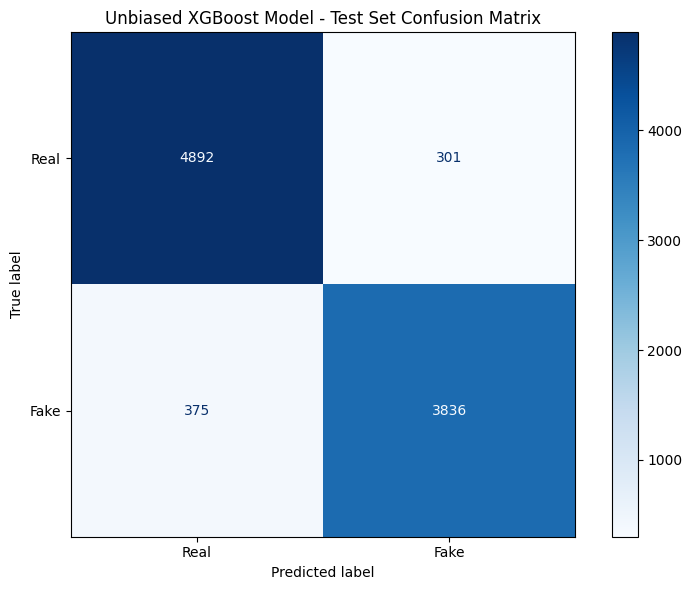

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Compute the confusion matrix
cm_unbiased = confusion_matrix(y_test, y_pred_test)

# 2. Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_unbiased,
    display_labels=["Real", "Fake"]
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Unbiased XGBoost Model - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()